# Rare-event constrained policy learning with large deviations

Companion notebook for the paper *Rare Event Constrained Reinforcement Learning with Large Deviations*.

**Setting.** We control a real system. We can choose actions and observe what happens, but we cannot reset the system to a chosen state and we cannot change its randomness. Failure must stay below a small probability $\delta$, also while we learn. In the code the "real system" is a simulated damage chain, but the learning methods only use the transitions they observe. The true model is used **only to check** the answers.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq

rnd = np.random.default_rng(2026)

# colours used in all plots
BLUE, ORANGE, GREEN, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#52514e"
plt.rcParams.update({"figure.figsize": (6, 3.5), "lines.linewidth": 2,
                     "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

## The damage chain

The state $x \in \{0, 1, \dots, N\}$ is accumulated damage. State $0$ is safe termination and state $N$ is failure; both are absorbing. In every other state the controller picks the safe mode $\mathsf{s}$ or the risky mode $\mathsf{r}$. Mode $u$ moves the damage up by one with probability $q_u$ and down by one otherwise. The risky mode is cheaper per step.

The policy is $\pi_\theta(\mathsf{r} \mid x) = \theta$, so the damage moves up with probability $q_\theta = (1-\theta) q_{\mathsf s} + \theta q_{\mathsf r}$.

In [2]:
N = 20          
x0 = 2          
T = 100        
delta = 1e-5    

q_safe, q_risky = 0.2, 0.4     
C_safe, C_risky = 1.0, 0.25    
c = N - x0                      

The next two functions compute the exact failure probability $p_\theta(x_0)$ and the expected cost $J(\theta)$ by backward recursion. They use the true model, so we use them only to check results.

In [3]:
def up_prob(theta):
    return (1 - theta) * q_safe + theta * q_risky

def failure_prob(theta, T=T):
    q = up_prob(theta)
    h = np.zeros(N + 1)
    h[N] = 1.0
    for _ in range(T):
        h_new = np.zeros(N + 1)
        h_new[N] = 1.0
        for x in range(1, N):
            h_new[x] = q * h[x + 1] + (1 - q) * h[x - 1]
        h = h_new
    return h[x0]

def expected_cost(theta, T=T):
    q = up_prob(theta)
    cost = (1 - theta) * C_safe + theta * C_risky
    J = np.zeros(N + 1)
    for _ in range(T):
        J_new = np.zeros(N + 1)
        for x in range(1, N):
            J_new[x] = cost + q * J[x + 1] + (1 - q) * J[x - 1]
        J = J_new
    return J[x0]

In [4]:
for theta in [0, 0.5, 1]:
    print(f"theta = {theta:.1f}:  p = {failure_prob(theta):.3e},  J = {expected_cost(theta):.3f}")

theta_star = brentq(lambda t: failure_prob(t) - delta, 1e-9, 1)
J_star = expected_cost(theta_star)
print(f"\nExact constrained optimum: theta* = {theta_star:.4f},  J = {J_star:.3f}")
print(f"Crude Monte Carlo near theta*: about {1 / (0.01 * failure_prob(theta_star)):.1e} "
      f"episodes for a 10% relative error")

theta = 0.0:  p = 1.364e-11,  J = 3.333
theta = 0.5:  p = 1.937e-07,  J = 3.125
theta = 1.0:  p = 3.082e-04,  J = 2.457

Exact constrained optimum: theta* = 0.7505,  J = 2.914
Crude Monte Carlo near theta*: about 1.0e+07 episodes for a 10% relative error


The cost goes down when $\theta$ goes up, and the failure probability goes up. The risky mode is worth using only when $C_{\mathsf r}/C_{\mathsf s} = 0.25 < (1-2q_{\mathsf r})/(1-2q_{\mathsf s}) = 1/3$, otherwise the longer episodes would cancel the cheaper steps.

## Why we do not try to sample failures

The optimal zero-variance way to estimate $p_\theta(x_0)$ is the Doob $h$-transform. It changes both the action probabilities and the transition probabilities. On the real system we can only change the actions. The action part of the Doob transform is

$$\tilde\pi_t(u \mid x) = \pi_\theta(u \mid x)\, \frac{g_t(x,u)}{h_t(x)}, \qquad
g_t(x,u) = \sum_{x'} P(x' \mid x, u)\, h_{t+1}(x').$$

Sampling actions from $\tilde\pi$ and weighting by $\pi/\tilde\pi$ gives an estimator with second moment at most $p$. If every action can lead to failure, the second moment is exactly $p$, which is the same as crude Monte Carlo. In our chain both modes can move the damage up, so this holds. We check it on a small chain.

In [5]:
N_s, T_s, theta_s = 8, 40, 0.5
q_mode = [q_safe, q_risky]
pi_mode = [1 - theta_s, theta_s]

h = np.zeros((T_s + 1, N_s + 1))
g = np.zeros((T_s, N_s + 1, 2))
h[:, N_s] = 1.0
for t in range(T_s - 1, -1, -1):
    for x in range(1, N_s):
        for u in (0, 1):
            g[t, x, u] = q_mode[u] * h[t + 1, x + 1] + (1 - q_mode[u]) * h[t + 1, x - 1]
        h[t, x] = pi_mode[0] * g[t, x, 0] + pi_mode[1] * g[t, x, 1]
p_small = h[0, x0]

def one_estimate(use_tilt):
    x, weight = x0, 1.0
    for t in range(T_s):
        if x == 0 or x == N_s:
            break
        if use_tilt and h[t, x] > 0:
            b = pi_mode[1] * g[t, x, 1] / h[t, x]  
        else:
            b = pi_mode[1]
        u = int(rnd.random() < b)
        weight *= pi_mode[u] / (b if u == 1 else 1 - b)
        x += 1 if rnd.random() < q_mode[u] else -1  
    return weight * (x == N_s)

for use_tilt in [False, True]:
    Y = np.array([one_estimate(use_tilt) for _ in range(200_000)])
    name = "action tilt" if use_tilt else "crude MC   "
    print(f"{name}: mean = {Y.mean():.3e}, E[Y^2] = {(Y**2).mean():.3e}, "
          f"failures seen = {(Y > 0).mean():.4f}   (true p = {p_small:.3e})")

crude MC   : mean = 4.960e-03, E[Y^2] = 4.960e-03, failures seen = 0.0050   (true p = 5.045e-03)
action tilt: mean = 4.954e-03, E[Y^2] = 5.122e-03, failures seen = 0.0084   (true p = 5.045e-03)


Failures are seen more often with the action tilt, but the second moment is the same. (The action tilt only helps when some action makes failure impossible: it can then skip that action. It never changes the randomness of the environment.) What makes failure rare is the randomness of the environment, and we cannot change it. So we need a quantity that we can learn from **typical** behaviour.

## Cramér's theorem and the Lundberg coefficient

**Cumulant generating function (CGF).** For one step $\xi = \pm 1$ with up-probability $q$,

$$\kappa(\lambda) = \log \mathbb{E}[e^{\lambda \xi}] = \log\!\big(q e^{\lambda} + (1-q) e^{-\lambda}\big).$$

**Cramér's theorem.** For $n$ independent steps, the average velocity is close to $v$ with probability about $e^{-n I(v)}$, where

$$I(v) = \sup_\lambda \big\{\lambda v - \kappa(\lambda)\big\}$$

is the rate function. It is zero at the mean velocity $1 - 2q$ and positive elsewhere.

**Lundberg coefficient.** If the drift is negative, $\kappa$ has a second root $\lambda^\star > 0$. Then $e^{\lambda^\star S_n}$ is a martingale and the probability of ever climbing a distance $c$ is at most $e^{-\lambda^\star c}$.

In [6]:
def cgf(q, lam):
    return np.log(q * np.exp(lam) + (1 - q) * np.exp(-lam))

def rate_function(q, v):
    lams = np.linspace(-15, 15, 30001)
    return np.max(lams * v - cgf(q, lams))

def lundberg(q):
    return brentq(lambda lam: cgf(q, lam), 1e-9, 30)

We check four facts for $q = q_{\theta^\star}$:

1. The rate function equals the relative entropy $\mathrm{KL}\big(\mathrm{Ber}(\tfrac{1+v}{2}) \,\|\, \mathrm{Ber}(q)\big)$.
2. $\lambda^\star = \log\big((1-q)/q\big)$.
3. $\lambda^\star = \min_{v > 0} I(v)/v$: the Lundberg coefficient is the cheapest rate **per unit of distance**. This is how ruin connects to Cramér's theorem.
4. Tilting a step by $e^{\lambda^\star \xi}$ swaps $q$ and $1-q$. This tilted walk is the walk conditioned to fail (the Doob $h$-transform with $h(x) = e^{\lambda^\star(x - N)}$).

In [7]:
q = up_prob(theta_star)

v = 0.3
a = (1 + v) / 2
kl = a * np.log(a / q) + (1 - a) * np.log((1 - a) / (1 - q))
print(f"1. rate function at v = {v}: {rate_function(q, v):.6f},  KL = {kl:.6f}")

lam_star = lundberg(q)
print(f"2. Lundberg coefficient: {lam_star:.6f},  log((1-q)/q) = {np.log((1 - q) / q):.6f}")

vs = np.linspace(0.01, 0.99, 981)
ratio = np.array([rate_function(q, v) / v for v in vs])
print(f"3. min_v rate(v)/v = {ratio.min():.6f} at v = {vs[ratio.argmin()]:.2f}  "
      f"(mean velocity of the tilted walk: 1 - 2q = {1 - 2*q:.2f})")

q_tilt = q * np.exp(lam_star) / np.exp(cgf(q, lam_star))
print(f"4. tilted up-probability = {q_tilt:.4f},  1 - q = {1 - q:.4f}")

1. rate function at v = 0.3: 0.185569,  KL = 0.185569
2. Lundberg coefficient: 0.618562,  log((1-q)/q) = 0.618562
3. min_v rate(v)/v = 0.618562 at v = 0.30  (mean velocity of the tilted walk: 1 - 2q = 0.30)
4. tilted up-probability = 0.6499,  1 - q = 0.6499


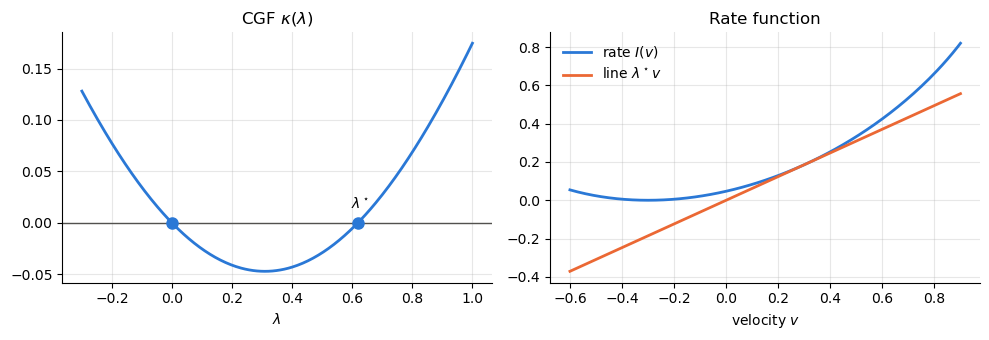

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5))

lam = np.linspace(-0.3, 1.0, 300)
ax1.plot(lam, cgf(q, lam), color=BLUE)
ax1.axhline(0, color=GREY, lw=1)
ax1.plot([0, lam_star], [0, 0], "o", color=BLUE, ms=8)
ax1.annotate(r"$\lambda^\star$", (lam_star, 0), textcoords="offset points", xytext=(-5, 10))
ax1.set_xlabel(r"$\lambda$")
ax1.set_title(r"CGF $\kappa(\lambda)$")

vv = np.linspace(-0.6, 0.9, 151)
ax2.plot(vv, [rate_function(q, v) for v in vv], color=BLUE, label=r"rate $I(v)$")
ax2.plot(vv, lam_star * vv, color=ORANGE, label=r"line $\lambda^\star v$")
ax2.set_xlabel("velocity $v$")
ax2.set_title("Rate function")
ax2.legend(frameon=False)
plt.tight_layout()
plt.savefig("fig_cgf_rate.pdf", bbox_inches="tight")   
plt.show()

The line $\lambda^\star v$ touches the rate function at $v = 1 - 2q$. A path to failure that climbs at speed $v$ costs $c\,I(v)/v$, and the cheapest one costs $c\,\lambda^\star$. So $e^{-\lambda^\star c}$ is the large-deviation estimate of the failure probability, and the Lundberg argument makes it an upper bound.

In [9]:
r = (1 - q) / q
p_inf = (1 - r**x0) / (1 - r**N)            
print(f"Lundberg bound e^(-lam* c) = {np.exp(-lam_star * c):.3e}")
print(f"exact (no horizon)         = {p_inf:.3e}")

Lundberg bound e^(-lam* c) = 1.461e-05
exact (no horizon)         = 1.037e-05


## The safety certificate

In the MDP the transition law depends on the action, so we use the **policy CGF**

$$\kappa_\theta(\lambda) = \log \sum_u \pi_\theta(u)\, e^{\kappa(u;\lambda)}.$$

Corollary 1 of the paper gives, for every horizon $T$,

$$p_\theta(x_0) \le B_\theta = \min_{\lambda \ge 0} \exp\!\big(-\lambda c + T\,[\kappa_\theta(\lambda)]^+\big).$$

For $\lambda \le \lambda^\star$ the time term is zero and we get Lundberg's bound. Larger $\lambda$ helps when the horizon is short.

In [10]:
LAMS = np.linspace(0, 3, 601)   

def certificate(policy_cgf, T=T):
    exponent = -LAMS * c + T * np.maximum(policy_cgf, 0)
    return np.exp(exponent.min())

def true_policy_cgf(theta):
    return np.log((1 - theta) * np.exp(cgf(q_safe, LAMS)) + theta * np.exp(cgf(q_risky, LAMS)))

In [11]:
print(" theta    T        p          B       B/p")
ratios = []
for theta in [0, 0.25, 0.5, 0.75, 1]:
    for TT in [20, 30, 60, 100, 1000]:
        p = failure_prob(theta, TT)
        B = certificate(true_policy_cgf(theta), TT)
        ratios.append(B / p)
        if TT in (30, 100) and theta in (0, 0.75, 1):
            print(f" {theta:4.2f}  {TT:4d}  {p:.3e}  {B:.3e}  {B/p:5.2f}")
print(f"\nAll 25 cases valid: {min(ratios) >= 1},  B/p between {min(ratios):.2f} and {max(ratios):.2f}")

 theta    T        p          B       B/p
 0.00    30  8.760e-12  1.455e-11   1.66
 0.00   100  1.364e-11  1.489e-11   1.09
 0.75    30  8.881e-07  2.850e-06   3.21
 0.75   100  9.920e-06  1.465e-05   1.48
 1.00    30  1.256e-05  4.345e-05   3.46
 1.00   100  3.082e-04  6.823e-04   2.21

All 25 cases valid: True,  B/p between 1.09 and 3.46


**Tightness.** Let the distance $c = (1-\beta)N$ and the horizon $T = \gamma N$ grow together. Then $-\tfrac1N \log p$ converges to $r = \sup_{\lambda \ge 0}\big[\lambda (1-\beta) - \gamma\, \kappa_\theta^+(\lambda)\big]$, which is exactly the exponent of the certificate. So the certificate loses nothing on the exponential scale.

In [12]:
def failure_prob_scaled(q, NN, start, TT):
    h = np.zeros(NN + 1)
    h[NN] = 1.0
    for _ in range(TT):
        h_new = np.zeros(NN + 1)
        h_new[NN] = 1.0
        h_new[1:NN] = q * h[2:] + (1 - q) * h[:NN - 1]
        h = h_new
    return h[start]

beta, gamma = 0.1, 6.0
lams = np.linspace(0, 6, 60001)
r = np.max(lams * (1 - beta) - gamma * np.maximum(cgf(q_risky, lams), 0))
for NN in [20, 100, 400]:
    p = failure_prob_scaled(q_risky, NN, int(beta * NN), int(gamma * NN))
    print(f"N = {NN:3d}:  -(1/N) log p = {-np.log(p) / NN:.4f}   (rate r = {r:.4f})")

N =  20:  -(1/N) log p = 0.3993   (rate r = 0.3649)
N = 100:  -(1/N) log p = 0.3659   (rate r = 0.3649)
N = 400:  -(1/N) log p = 0.3649   (rate r = 0.3649)


## Learning the certificate from data

The transition law of each action does not depend on the policy. So transitions observed under **any** policy tell us about **every** policy. We only need upper bounds on

$$M(u;\lambda) = \mathbb{E}\big[e^{\lambda \xi} \mid u\big].$$

Lemma 2 of the paper: with $n$ observed steps of action $u$, with probability at least $1-\eta$, for all actions, all $\lambda$ in the grid and all sample sizes $n$,

$$M(u;\lambda) \le \hat M(u;\lambda) + \big(e^{\lambda} - e^{-\lambda}\big)
\sqrt{\frac{\log\!\big(|\mathcal U|\, L\, n(n+1)/\eta\big)}{2n}},$$

where $L$ is the number of grid points. The factor $n(n+1)$ makes the bound hold for every $n$ at once, so we can keep adding data while the policy changes.

An action that was never tried gets $M = \infty$: a policy that uses it cannot be certified.

In [13]:
def mgf_upper(n_up, n_down, eta):
    n = n_up + n_down
    if n == 0:
        return np.full(len(LAMS), np.inf)
    mean = (n_up * np.exp(LAMS) + n_down * np.exp(-LAMS)) / n
    width = (np.exp(LAMS) - np.exp(-LAMS)) * np.sqrt(np.log(2 * len(LAMS) * n * (n + 1) / eta) / (2 * n))
    return mean + width

def certified_bound(theta, data, eta=0.05):
    M_s = mgf_upper(*data["safe"], eta)
    M_r = mgf_upper(*data["risky"], eta)
    if theta == 0:
        mix = M_s
    elif theta == 1:
        mix = M_r
    else:
        mix = (1 - theta) * M_s + theta * M_r
    return certificate(np.log(mix))

def largest_certified_theta(data, eta=0.05):
    if certified_bound(0.0, data, eta) > delta:
        return 0.0
    if certified_bound(1.0, data, eta) <= delta:
        return 1.0
    return brentq(lambda t: certified_bound(t, data, eta) - delta, 0, 1, xtol=1e-6)

First a check of the certificate itself. We observe $n$ steps under the behaviour policy $\theta_b = 0.5$ and compute the largest certified $\theta$. We repeat this for 200 independent data sets. Because the damage chain has a single cell (the transition law does not depend on the state), we can generate the observed steps directly.

In [14]:
def observe_steps(theta_b, n, gen=rnd):
    risky = gen.random(n) < theta_b
    up = np.where(risky, gen.random(n) < q_risky, gen.random(n) < q_safe)
    return {"safe":  [int(np.sum(up & ~risky)), int(np.sum(~up & ~risky))],
            "risky": [int(np.sum(up & risky)),  int(np.sum(~up & risky))]}

print("      n   some policy certified   safe in   median theta   median cost above optimum")
for n in [10**3, 10**4, 10**5]:
    safe, costs, thetas_c, any_cert = [], [], [], []
    for rep in range(200):
        data = observe_steps(0.5, n)
        th = largest_certified_theta(data)
        any_cert.append(certified_bound(0.0, data) <= delta)
        safe.append(failure_prob(th) <= delta)
        costs.append(expected_cost(th))
        thetas_c.append(th)
    print(f" {n:6d}         {100*np.mean(any_cert):5.1f}%          {100*np.mean(safe):5.1f}%      {np.median(thetas_c):.3f}        {100*(np.median(costs)/J_star - 1):5.1f}%")

th_c = brentq(lambda t: certificate(true_policy_cgf(t)) - delta, 1e-9, 1)
print(f"\nWith the exact CGFs: certified theta <= {th_c:.4f},  cost {100*(expected_cost(th_c)/J_star - 1):.1f}% above optimum")

      n   some policy certified   safe in   median theta   median cost above optimum
   1000          42.0%          100.0%      0.000         14.4%
  10000         100.0%          100.0%      0.466          7.9%
 100000         100.0%          100.0%      0.638          3.8%

With the exact CGFs: certified theta <= 0.7265,  cost 0.9% above optimum


No failure is observed in any of these data sets. The certified policy is always safe, and the price for the guarantee goes down as data grow.

**The bound for every policy.** We take one data set of each size and compute the bound for every $\theta$ from the same data. The largest certified policy is where the bound crosses $\delta$.

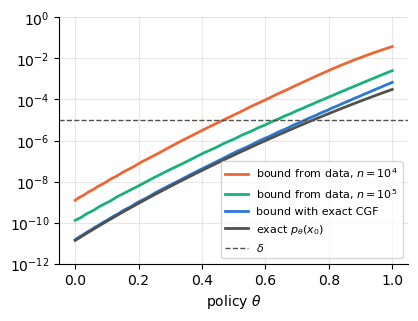

largest certified theta: data n=1e4 0.469, data n=1e5 0.634, exact CGF 0.726, exact 0.751


In [15]:
gen = np.random.default_rng(1)  
data_small = observe_steps(0.5, 10**4, gen)
data_large = observe_steps(0.5, 10**5, gen)

thetas = np.linspace(0, 1, 101)
exact = [failure_prob(t) for t in thetas]
bound_exact_cgf = [certificate(true_policy_cgf(t)) for t in thetas]
bound_small = [certified_bound(t, data_small) for t in thetas]
bound_large = [certified_bound(t, data_large) for t in thetas]

fig, ax = plt.subplots(figsize=(4.5, 3.2))
ax.semilogy(thetas, bound_small, color=ORANGE, label=r"bound from data, $n=10^4$")
ax.semilogy(thetas, bound_large, color=GREEN, label=r"bound from data, $n=10^5$")
ax.semilogy(thetas, bound_exact_cgf, color=BLUE, label="bound with exact CGF")
ax.semilogy(thetas, exact, color=GREY, label=r"exact $p_\theta(x_0)$")
ax.axhline(delta, color=GREY, lw=1, ls="--", label=r"$\delta$")
ax.set_xlabel(r"policy $\theta$")
ax.set_ylim(1e-12, 1)
ax.legend(loc="lower right", fontsize=8)
plt.savefig("fig_bound_vs_theta.pdf", bbox_inches="tight")   
plt.show()

print(f"largest certified theta: data n=1e4 {largest_certified_theta(data_small):.3f}, "
      f"data n=1e5 {largest_certified_theta(data_large):.3f}, exact CGF {th_c:.3f}, exact {theta_star:.3f}")

## Certified policy improvement

Now the policy changes while we learn. Every policy we **run** on the system must be safe. The certificate only needs data, not the policy we are going to run, so we can check a new policy **before** running it.

**Algorithm.**
1. Start from a policy $\theta_0$ that is known to be safe.
2. Run the current policy for $E$ episodes. Add the observed steps to the data.
3. Estimate the gradient of the cost from these episodes (costs are not rare).
4. Take a gradient step. If the new policy is not certified, halve the step until it is.

The cost gradient uses the score-function estimator with the cost-to-go of each step and the mean cost-to-go as baseline. For comparison we also run a primal-dual method on the same certificate and the same gradient estimate.

In [16]:
def run_episodes(theta, E):
    counts = {"safe": [0, 0], "risky": [0, 0]}
    episodes = []
    for i in range(E):
        x, t, step_costs, step_scores = x0, 0, [], []
        while t < T and 0 < x < N:
            risky = rnd.random() < theta
            step_costs.append(C_risky if risky else C_safe)
            step_scores.append(1 / theta if risky else -1 / (1 - theta))
            up = rnd.random() < (q_risky if risky else q_safe)
            counts["risky" if risky else "safe"][0 if up else 1] += 1
            x += 1 if up else -1
            t += 1
        cost_to_go = np.cumsum(step_costs[::-1])[::-1]
        episodes.append((np.array(step_scores), cost_to_go))
    return counts, episodes

def cost_gradient(episodes):
    baseline = np.concatenate([ctg for _, ctg in episodes]).mean()
    return sum(np.sum(sc * (ctg - baseline)) for sc, ctg in episodes) / len(episodes)

def add(data, counts):
    for a in data:
        data[a][0] += counts[a][0]
        data[a][1] += counts[a][1]

In [17]:
K, E, alpha = 60, 400, 0.05
theta0 = 0.05     

def certified_improvement():
    data = {"safe": [0, 0], "risky": [0, 0]}
    theta, history = theta0, []
    accepted = {theta0}          
    for k in range(K):
        ok = theta in accepted   
        counts, episodes = run_episodes(theta, E)
        add(data, counts)
        history.append([theta, failure_prob(theta), expected_cost(theta), ok])
        new = float(np.clip(theta - alpha * cost_gradient(episodes), 0.001, 0.999))
        for _ in range(30):                       
            if certified_bound(new, data) <= delta:
                break
            new = 0.5 * (new + theta)
        if certified_bound(new, data) <= delta:
            accepted.add(new)
        else:
            new = theta          
        theta = new
    return np.array(history)

def primal_dual(beta):
    data = {"safe": [0, 0], "risky": [0, 0]}
    theta, mu, history = theta0, 0.0, []
    for k in range(K):
        ok = (theta == theta0) or (certified_bound(theta, data) <= delta)
        counts, episodes = run_episodes(theta, E)
        add(data, counts)
        history.append([theta, failure_prob(theta), expected_cost(theta), ok])
        B_now = certified_bound(theta, data)
        e = 1e-4                                  
        dlogB = (np.log(certified_bound(min(theta + e, 0.999), data))
                 - np.log(certified_bound(max(theta - e, 0.001), data))) / (2 * e)
        theta = float(np.clip(theta - alpha * (cost_gradient(episodes) + mu * dlogB), 0.001, 0.999))
        mu = max(0.0, mu + beta * (np.log(B_now) - np.log(delta)))
    return np.array(history)

H_cert = certified_improvement()
H_pd = {b: primal_dual(b) for b in [0.05, 0.5]}

def summary(name, H):
    print(f"{name}: final theta {H[-1,0]:.3f}, final cost {H[-1,2]:.3f}, "
          f"max true p {H[:,1].max():.1e}, rounds with p > delta: {int((H[:,1] > delta).sum())}, "
          f"rounds run without a certificate: {int((H[:,3] == 0).sum())}")

summary("certified       ", H_cert)
for b, H in H_pd.items():
    summary(f"primal-dual b={b:<4}", H)

certified       : final theta 0.640, final cost 3.023, max true p 1.9e-06, rounds with p > delta: 0, rounds run without a certificate: 0
primal-dual b=0.05: final theta 0.475, final cost 3.140, max true p 2.6e-05, rounds with p > delta: 2, rounds run without a certificate: 20
primal-dual b=0.5 : final theta 0.619, final cost 3.040, max true p 2.0e-05, rounds with p > delta: 2, rounds run without a certificate: 11


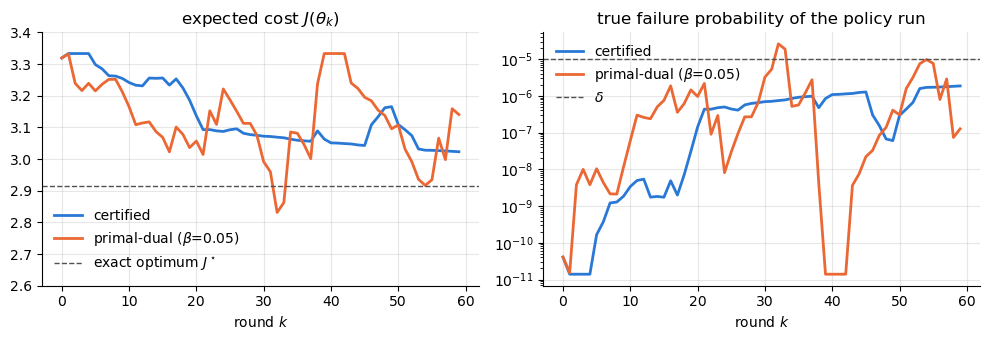

In [18]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5))
rounds = np.arange(K)

ax1.plot(rounds, H_cert[:, 2], color=BLUE, label="certified")
ax1.plot(rounds, H_pd[0.05][:, 2], color=ORANGE, label=r"primal-dual ($\beta$=0.05)")
ax1.axhline(J_star, color=GREY, lw=1, ls="--", label=r"exact optimum $J^\star$")
ax1.set_xlabel("round $k$")
ax1.set_title(r"expected cost $J(\theta_k)$")
# leave room below the curves for the legend
ax1.set_ylim(2.6, 3.4)
ax1.legend(frameon=False, loc="lower left")

ax2.semilogy(rounds, H_cert[:, 1], color=BLUE, label="certified")
ax2.semilogy(rounds, H_pd[0.05][:, 1], color=ORANGE, label=r"primal-dual ($\beta$=0.05)")
ax2.axhline(delta, color=GREY, lw=1, ls="--", label=r"$\delta$")
ax2.set_xlabel("round $k$")
ax2.set_title(r"true failure probability of the policy run")
ax2.legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.savefig("fig_certified_learning.pdf", bbox_inches="tight")   # used in the paper
plt.show()

The certified method only moves when the data allow it. Every policy it runs was checked before it was run, and since Lemma 2 holds for all sample sizes at once, a policy that passed the check once stays safe with probability at least $1-\eta$. The primal-dual method moves first and corrects later through the multiplier, so some of the policies it runs have no certificate at that time, and depending on the step size some of them are not safe.

## State-dependent damage and unvisited regions

Now damage accelerates near failure: $q = 0.2$ for $x < 12$ and $q = 0.45$ for $x \ge 12$. There is no control in this section; we only look at the certificate. We split the states into two cells, $A = \{x < 12\}$ and $B = \{x \ge 12\}$.

Corollary 2 of the paper: if the decay rate $s_k$ in each cell is between $0$ and the cell's Lundberg coefficient, and the decay rates do not increase with damage, then

$$p \le \exp\Big(-\sum_k s_k\, \ell_k\Big),$$

where $\ell_k$ is the length of cell $k$ between $x_0$ and $N$. A cell with no data gets decay rate $0$. This is valid whatever happens in that cell.

In [19]:
q_of_x = np.array([0.2 if x < 12 else 0.45 for x in range(N + 1)])

def ruin_prob(q_of_x):
    r = (1 - q_of_x[1:N]) / q_of_x[1:N] # true prob
    prods = np.concatenate([[1.0], np.cumprod(r)])
    return prods[:x0].sum() / prods[:N].sum()

p_true = ruin_prob(q_of_x)
lam_A, lam_B = lundberg(0.2), lundberg(0.45)
print(f"true p                                     = {p_true:.3e}")
print(f"one decay rate for all states (worst case) = {np.exp(-lam_B * c):.3e}")
B_two = np.exp(-(lam_A * (12 - x0) + lam_B * (N - 12)))
print(f"two decay rates, exact Lundberg coeffs     = {B_two:.3e}   ({B_two / p_true:.1f} x true)")

true p                                     = 5.134e-08
one decay rate for all states (worst case) = 2.700e-02
two decay rates, exact Lundberg coeffs     = 1.915e-07   (3.7 x true)


Now learn from normal operation only. We run 200,000 episodes from $x_0$ and record the steps in each cell.

In [20]:
counts = {"A": [0, 0], "B": [0, 0]}
visits = np.zeros(N + 1)
ups = np.zeros(N + 1)
highest = x0
for _ in range(200_000):
    x = x0
    while 0 < x < N:
        up = rnd.random() < q_of_x[x]
        counts["A" if x < 12 else "B"][0 if up else 1] += 1
        visits[x] += 1
        ups[x] += up
        x += 1 if up else -1
        highest = max(highest, x)
print(f"highest state reached: {highest},  steps in cell A: {sum(counts['A'])},  in cell B: {sum(counts['B'])}")

def lundberg_lower(n_up, n_down, eta=0.05, n_cells=2):
    M_up = mgf_upper(n_up, n_down, eta / n_cells)
    ok = np.log(M_up) <= 0
    return LAMS[ok].max() if ok.any() else 0.0

s_A = lundberg_lower(*counts["A"])
s_B = min(s_A, lundberg_lower(*counts["B"]))     
B_data = np.exp(-(s_A * (12 - x0) + s_B * (N - 12)))
print(f"learned decay rates: s_A = {s_A:.3f} (true {lam_A:.3f}),  s_B = {s_B:.3f}")
print(f"certificate from data = {B_data:.3e}")

for qB in [0.6, 0.9, 0.99]:
    q_test = np.array([0.2 if x < 12 else qB for x in range(N + 1)])
    print(f"   still valid if q in cell B were {qB}: {ruin_prob(q_test) <= B_data}")

highest state reached: 10,  steps in cell A: 663986,  in cell B: 0
learned decay rates: s_A = 1.360 (true 1.386),  s_B = 0.000
certificate from data = 1.240e-06
   still valid if q in cell B were 0.6: True
   still valid if q in cell B were 0.9: True
   still valid if q in cell B were 0.99: True


For comparison, fit a transition model to the same data. States with few visits borrow the average up-probability of all observed steps.

In [21]:
q_fit = np.where(visits > 30, ups / np.maximum(visits, 1), ups.sum() / visits.sum())
q_fit[0], q_fit[N] = 0.5, 0.5     
p_fit = ruin_prob(q_fit)
print(f"fitted model predicts p = {p_fit:.1e},  which is {p_true / p_fit:.0f} times too small")

fitted model predicts p = 1.4e-11,  which is 3662 times too small


The fitted model is far too optimistic because it has never seen cell $B$. The certificate is larger than the true value, but it stays valid however bad cell $B$ is.